# DCC 2026 Mission 2 Stage 5 — M00 vs M01 Model Experiments

이 Notebook은 실제 성능 결론을 저장하지 않는다. 동일한 E05 42D standardized input에서 선형 `LogisticRegression`과 비선형 `HistGradientBoostingClassifier`를 공정하게 비교하도록 사용자가 직접 실행하는 절차만 제공한다.

모든 실행 switch의 저장 source 기본값은 `False`이다. 실제 competition data 학습과 Official Validation은 자동으로 실행되지 않는다.


In [18]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
from IPython.display import display

REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == 'notebooks':
    REPO_ROOT = REPO_ROOT.parent
SRC_ROOT = REPO_ROOT / 'src'
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from dcc_data.mission2_model_experiments import (
    CACHE_BACKEND as MODULE_CACHE_BACKEND,
    E05_FEATURE_NAMES,
    EXPECTED_INTERNAL_SPLIT,
    EXPECTED_OFFICIAL_CALLS,
    EXPECTED_OFFICIAL_ROWS,
    FROZEN_E05_OFFICIAL_REFERENCE,
    M00_LOGISTIC_REGRESSION_CONFIG,
    M01_HGB_CONFIG,
    augment_model_report,
    build_standalone_diagnostic_report,
    build_decision_table,
    build_m01_model,
    compare_model_results,
    compare_official_model_results,
    config_fingerprint,
    prepare_internal_comparison,
    load_standalone_e05_cache,
    prepare_official_comparison,
    run_internal_m00,
    run_internal_m01,
    run_official_m00,
    run_official_m01,
    standalone_group_split_indices,
    standalone_training_cache_paths,
    standalone_validation_cache_paths,
    validate_e05_contract,
    validate_m00_official_reproducibility,
)

CACHE_BACKEND = "standalone_adapter"
assert MODULE_CACHE_BACKEND == CACHE_BACKEND

prepared_internal = None
m00_internal_result = None
m01_internal_result = None
m00_internal_report = None
m01_internal_report = None
internal_comparison = None
prepared_official = None
validation_cache = None
m00_official_result = None
m00_official_report = None
m00_official_reproducibility = None
m01_official_result = None
m01_official_report = None
official_comparison = None

print('CACHE_BACKEND:', CACHE_BACKEND)
print('Feature contract:', E05_FEATURE_NAMES)
print('Feature dimension:', len(E05_FEATURE_NAMES))
print('Automatic extraction:', False)
print('Model configs frozen:', dict(M00_LOGISTIC_REGRESSION_CONFIG), dict(M01_HGB_CONFIG))
print('All checkpoint-local competition execution switches are False in saved source.')


CACHE_BACKEND: standalone_adapter
Feature contract: ('mfcc_01_mean', 'mfcc_02_mean', 'mfcc_03_mean', 'mfcc_04_mean', 'mfcc_05_mean', 'mfcc_06_mean', 'mfcc_07_mean', 'mfcc_08_mean', 'mfcc_09_mean', 'mfcc_10_mean', 'mfcc_11_mean', 'mfcc_12_mean', 'mfcc_13_mean', 'mfcc_14_mean', 'mfcc_15_mean', 'mfcc_16_mean', 'mfcc_17_mean', 'mfcc_18_mean', 'mfcc_19_mean', 'mfcc_20_mean', 'mfcc_01_std', 'mfcc_02_std', 'mfcc_03_std', 'mfcc_04_std', 'mfcc_05_std', 'mfcc_06_std', 'mfcc_07_std', 'mfcc_08_std', 'mfcc_09_std', 'mfcc_10_std', 'mfcc_11_std', 'mfcc_12_std', 'mfcc_13_std', 'mfcc_14_std', 'mfcc_15_std', 'mfcc_16_std', 'mfcc_17_std', 'mfcc_18_std', 'mfcc_19_std', 'mfcc_20_std', 'spectral_rolloff', 'zcr')
Feature dimension: 42
Automatic extraction: False
Model configs frozen: {'solver': 'lbfgs', 'max_iter': 1000, 'class_weight': None, 'random_state': 42} {'loss': 'log_loss', 'learning_rate': 0.1, 'max_iter': 100, 'max_leaf_nodes': 31, 'max_depth': None, 'min_samples_leaf': 20, 'l2_regularization': 0.

## Checkpoint A — Model Experiment Contract

1. **측정:** 모델 class만 선형 M00에서 비선형 M01로 바꿀 때 Accuracy가 달라지는지 측정한다.
2. **입력:** 실제 waveform에서 계산된 MFCC40 + `spectral_rolloff` + `zcr`, 정확히 42D만 사용한다.
3. **출력 의미:** feature 순서, 차원, scaler 정책, 모델 precommit을 실행 전에 고정한다.
4. **오류 조건:** text, annotation, 순서·시간·ID·overlap·quality metadata가 입력되거나 53D 계약이 섞이면 즉시 중단한다.
5. **다음 판단:** 이 계약이 통과해야 cache와 row alignment를 확인한다.

Checkpoint A--H는 `CACHE_BACKEND=standalone_adapter`를 사용하므로 PR #16 merge 여부와 독립적으로 실행된다. cache miss에서는 waveform extraction을 시작하지 않고 중단한다.


In [19]:
assert len(E05_FEATURE_NAMES) == 42
assert E05_FEATURE_NAMES[-2:] == ('spectral_rolloff', 'zcr')
assert M00_LOGISTIC_REGRESSION_CONFIG == {
    'solver': 'lbfgs', 'max_iter': 1000, 'class_weight': None, 'random_state': 42
}
assert M01_HGB_CONFIG['early_stopping'] is False
assert M01_HGB_CONFIG['random_state'] == 42
assert CACHE_BACKEND == 'standalone_adapter'
display(pd.DataFrame({
    'fixed_element': ['data/rows/labels/keys', 'feature', 'preprocessing', 'split', 'seed', 'metric/threshold'],
    'contract': ['identical', 'E05 exact 42D', 'shared StandardScaler', 'call_id GroupSplit', 42, 'Accuracy / predict threshold 0.5'],
}))
print('Changed major factor: LogisticRegression -> HistGradientBoostingClassifier')


,fixed_element,contract
0,data/rows/labels/keys,identical
1,feature,E05 exact 42D
2,preprocessing,shared StandardScaler
3,split,call_id GroupSplit
4,seed,42
5,metric/threshold,Accuracy / predict threshold 0.5


Changed major factor: LogisticRegression -> HistGradientBoostingClassifier


## Checkpoint B — Cache / Row Alignment

1. **측정:** 기존 immutable Training cache가 정확한 E05 row/label/feature 계약을 재현하는지 확인한다.
2. **입력:** 기존 Training manifest, frozen MFCC40 NPZ, candidate-feature Parquet/metadata만 읽는다.
3. **출력 의미:** 889,358개의 unique `record_key`, 정렬된 `y`, finite float32 42D matrix가 준비되었음을 뜻한다.
4. **오류 조건:** cache miss·metadata mismatch·key 중복/불일치·label mismatch·NaN/inf·차원 불일치면 자동 추출 없이 STOP한다.
5. **다음 판단:** 이 checkpoint가 통과해야 Training-only split을 한 번 만든다.


In [20]:
RUN_LOAD_TRAINING_CACHE = False
if not RUN_LOAD_TRAINING_CACHE:
    raise RuntimeError('STOP: cache 검토 후 Ctrl+F `RUN_LOAD_TRAINING_CACHE = False`를 이번 실행에서만 True로 바꾸세요.')
training_cache_paths = standalone_training_cache_paths(REPO_ROOT)
training_cache = load_standalone_e05_cache(
    training_cache_paths,
    split='Training',
    expected_rows=EXPECTED_OFFICIAL_ROWS['Training'],
    expected_calls=29_200,
)
validated_training = training_cache.validated
tracking_training = training_cache.tracking.reset_index(drop=True)
assert validated_training.X.dtype == np.float32
print('Training E05 contract:', validated_training.X.shape, validated_training.X.dtype)
print('Unique record_key:', len(np.unique(validated_training.record_keys)))
display(pd.DataFrame([dict(training_cache.cache_audit)]))


Training E05 contract: (889358, 42) float32
Unique record_key: 889358


,backend,split,rows,calls,canonical_order,record_key_signature,candidate_source_dtype,final_dtype,automatic_extraction
0,standalone_adapter,Training,889358,29200,frozen_mfcc_npz,7c1e27f4f45ce84f261467f5863fcf8df838a8f1b22dc2...,float64,float32,False


## Checkpoint C — Fixed Training-only GroupSplit

1. **측정:** 동일 통화가 internal train/validation 양쪽에 섞이지 않는 고정 split을 만든다.
2. **입력:** Training 889,358 rows와 tracking용 `call_id`만 사용하며 `call_id`는 모델 입력이 아니다.
3. **출력 의미:** seed=42, test_size=0.2, 예상 row/call 수, call overlap=0과 하나의 shared scaler가 확정된다.
4. **오류 조건:** 예상 count 불일치·call overlap·row partition 오류·scaler fit scope 위반이면 STOP한다.
5. **다음 판단:** 같은 indices와 scaler output을 M00과 M01 모두에 전달한다.


In [21]:
if 'validated_training' not in globals():
    raise RuntimeError('STOP: Checkpoint B를 먼저 통과하세요.')
assert np.array_equal(
    tracking_training['record_key'].astype(str).to_numpy(),
    validated_training.record_keys,
)
prepared_internal = prepare_internal_comparison(
    X=validated_training.X,
    y=validated_training.y,
    record_keys=validated_training.record_keys,
    call_ids=tracking_training['call_id'].astype(str).to_numpy(),
    feature_names=validated_training.feature_names,
    split_function=standalone_group_split_indices,
    expected_rows=EXPECTED_OFFICIAL_ROWS['Training'],
    expected_split_contract=EXPECTED_INTERNAL_SPLIT,
)
internal_training_tracking = tracking_training.iloc[prepared_internal.train_idx].reset_index(drop=True)
internal_validation_tracking = tracking_training.iloc[prepared_internal.validation_idx].reset_index(drop=True)
assert prepared_internal.scaler_fit_scope == 'internal_train_only'
assert prepared_internal.split_audit == dict(EXPECTED_INTERNAL_SPLIT) | {'seed': 42, 'test_size': 0.2}
display(pd.DataFrame([prepared_internal.split_audit]))
print('Shared scaled shapes:', prepared_internal.X_train_scaled.shape, prepared_internal.X_evaluation_scaled.shape)


,seed,test_size,total_rows,train_rows,validation_rows,train_calls,validation_calls,call_overlap
0,42,0.2,889358,711467,177891,23360,5840,0


Shared scaled shapes: (711467, 42) (177891, 42)


## Checkpoint D — M00 Internal LR Reference

1. **측정:** 이번 고정 internal split에서 42D standardized Logistic Regression reference를 실제로 측정한다.
2. **입력:** Checkpoint C의 internal train/validation arrays와 동일 shared scaler output만 사용한다.
3. **출력 의미:** M01 delta의 분모가 되는 실제 M00 Accuracy, confusion matrix, recall, errors와 slices이다.
4. **오류 조건:** `RUN_INTERNAL_M00=False`, prepared payload 부재, key/shape/확률 계약 위반이면 학습하지 않고 STOP한다.
5. **다음 판단:** M00 결과를 확인한 뒤에도 M01 config는 바꾸지 않는다.


In [22]:
RUN_INTERNAL_M00 = False
if not RUN_INTERNAL_M00:
    raise RuntimeError('STOP: Ctrl+F `RUN_INTERNAL_M00 = False`; 실제 internal M00 실행은 사용자 담당입니다.')
if prepared_internal is None:
    raise RuntimeError('STOP: Checkpoint C의 fixed split/scaler가 없습니다.')
m00_internal_result = run_internal_m00(prepared_internal, allow_fit=RUN_INTERNAL_M00)
m00_base_report = build_standalone_diagnostic_report(
    m00_internal_result,
    training_tracking=internal_training_tracking,
    evaluation_tracking=internal_validation_tracking,
)
m00_internal_report = augment_model_report(m00_internal_result, m00_base_report)
display(pd.DataFrame([{
    'experiment_id': m00_internal_result.experiment_id,
    'model_name': m00_internal_result.model_name,
    'model_config': dict(m00_internal_result.model_config),
    'feature_names': m00_internal_result.feature_names,
    'feature_dimension': len(m00_internal_result.feature_names),
    'internal_train_shape': m00_internal_result.train_shape,
    'internal_validation_shape': m00_internal_result.evaluation_shape,
    **m00_internal_result.metrics,
    'high_confidence_error_count': m00_internal_report['high_confidence_error_count'],
}]))
display(m00_internal_report['duration_summary'])
display(m00_internal_report['overlap_summary'])
display(m00_internal_report['confidence_summary'])


,experiment_id,model_name,model_config,feature_names,feature_dimension,internal_train_shape,internal_validation_shape,sample_count,accuracy,confusion_matrix,recall_0,recall_1,recall_speaker_0,recall_speaker_1,correct_count,high_confidence_error_count
0,M00,LogisticRegression,"{'solver': 'lbfgs', 'max_iter': 1000, 'class_w...","(mfcc_01_mean, mfcc_02_mean, mfcc_03_mean, mfc...",42,"(711467, 42)","(177891, 42)",177891,0.817332,"[[66321, 19030], [13465, 79075]]",0.777038,0.854495,0.777038,0.854495,145396,3383


,slice,count,accuracy
0,q25_q75,88589,0.804310
1,q75_q95,35967,0.880390
2,q05_q25,35746,0.768450
3,q00_q05,8687,0.785542
4,q95_q100,8902,0.919456


,slice,count,accuracy
0,no_overlap,99310,0.851445
1,overlap,78581,0.774220


,slice,count,accuracy
0,>=0.90,68205,0.950400
1,0.80-0.90,33093,0.881123
2,0.70-0.80,22313,0.793842
3,0.60-0.70,32053,0.655976
4,<0.60,22227,0.570297


M00(42D + Logistic Regression)은 internal Accuracy 81.73%를 기록했다. speaker 0 Recall(77.70%)이 speaker 1 Recall(85.45%)보다 낮았으며, overlap 발화와 비교적 짧은 발화에서 낮은 Accuracy가 관찰되었다. 반대로 긴 발화에서는 Accuracy가 높았다. 이는 원인 확정이 아니라 M01에서 개선 여부를 확인할 오류 패턴이다.

## Checkpoint E — M01 HGB Precommit

1. **측정:** 결과를 보기 전에 M01의 단일 HGB configuration이 정확히 고정되었는지 확인한다.
2. **입력:** 모델 parameter dictionary만 사용하며 data fit은 하지 않는다.
3. **출력 의미:** reproducible representation과 fingerprint가 같으면 사전 약속한 M01임을 뜻한다.
4. **오류 조건:** 어떤 parameter라도 바뀌거나 `early_stopping=False`가 아니면 STOP한다.
5. **다음 판단:** config를 수정하지 않은 채 별도 M01 실행 switch로 넘어간다.


In [23]:
expected_m01_config = {
    'loss': 'log_loss',
    'learning_rate': 0.1,
    'max_iter': 100,
    'max_leaf_nodes': 31,
    'max_depth': None,
    'min_samples_leaf': 20,
    'l2_regularization': 0.0,
    'max_bins': 255,
    'early_stopping': False,
    'random_state': 42,
}
assert M01_HGB_CONFIG == expected_m01_config
assert {key: build_m01_model().get_params()[key] for key in expected_m01_config} == expected_m01_config
print('M01 config:', json.dumps(dict(M01_HGB_CONFIG), sort_keys=True, indent=2))
print('M01 config fingerprint:', config_fingerprint(M01_HGB_CONFIG))
print('No model has been fit by this checkpoint.')


M01 config: {
  "early_stopping": false,
  "l2_regularization": 0.0,
  "learning_rate": 0.1,
  "loss": "log_loss",
  "max_bins": 255,
  "max_depth": null,
  "max_iter": 100,
  "max_leaf_nodes": 31,
  "min_samples_leaf": 20,
  "random_state": 42
}
M01 config fingerprint: cbcc4878fae9e15c0ccca68304bb3209ee24950a783803ed768b5398261d484d
No model has been fit by this checkpoint.


## Checkpoint F — M01 Internal Run

1. **측정:** M00과 동일한 internal rows와 standardized 42D input에서 precommitted HGB를 측정한다.
2. **입력:** Checkpoint C의 동일 `train_idx`, `validation_idx`, `y`, `record_key`, matrix, scaler만 사용한다.
3. **출력 의미:** 실제 M01 Accuracy와 진단 지표이며 개선 여부 자체는 아직 선언하지 않는다.
4. **오류 조건:** switch가 False이거나 M00과 공유 payload가 아니거나 class/probability 계약이 깨지면 STOP한다.
5. **다음 판단:** M00/M01 paired comparison을 수행해 변화 구조를 확인한다.


In [24]:
RUN_INTERNAL_M01 = False
if not RUN_INTERNAL_M01:
    raise RuntimeError('STOP: Ctrl+F `RUN_INTERNAL_M01 = False`; 실제 internal M01 실행은 사용자 담당입니다.')
if prepared_internal is None:
    raise RuntimeError('STOP: Checkpoint C의 fixed split/scaler가 없습니다.')
if m00_internal_result is None:
    raise RuntimeError('STOP: M01 전에 Checkpoint D의 M00 internal reference를 먼저 실행하세요.')
m01_internal_result = run_internal_m01(prepared_internal, allow_fit=RUN_INTERNAL_M01)
m01_base_report = build_standalone_diagnostic_report(
    m01_internal_result,
    training_tracking=internal_training_tracking,
    evaluation_tracking=internal_validation_tracking,
)
m01_internal_report = augment_model_report(m01_internal_result, m01_base_report)
display(pd.DataFrame([{
    'experiment_id': m01_internal_result.experiment_id,
    'model_name': m01_internal_result.model_name,
    'model_config': dict(m01_internal_result.model_config),
    'feature_names': m01_internal_result.feature_names,
    'feature_dimension': len(m01_internal_result.feature_names),
    'internal_train_shape': m01_internal_result.train_shape,
    'internal_validation_shape': m01_internal_result.evaluation_shape,
    **m01_internal_result.metrics,
    'high_confidence_error_count': m01_internal_report['high_confidence_error_count'],
}]))
display(m01_internal_report['duration_summary'])
display(m01_internal_report['overlap_summary'])
display(m01_internal_report['confidence_summary'])
print('Confidence slices are diagnostic only; they do not establish comparative calibration.')


,experiment_id,model_name,model_config,feature_names,feature_dimension,internal_train_shape,internal_validation_shape,sample_count,accuracy,confusion_matrix,recall_0,recall_1,recall_speaker_0,recall_speaker_1,correct_count,high_confidence_error_count
0,M01,HistGradientBoostingClassifier,"{'loss': 'log_loss', 'learning_rate': 0.1, 'ma...","(mfcc_01_mean, mfcc_02_mean, mfcc_03_mean, mfc...",42,"(711467, 42)","(177891, 42)",177891,0.841875,"[[68036, 17315], [10814, 81726]]",0.797132,0.883142,0.797132,0.883142,149762,1965


,slice,count,accuracy
0,q25_q75,88589,0.825441
1,q75_q95,35967,0.901132
2,q05_q25,35746,0.800901
3,q00_q05,8687,0.839185
4,q95_q100,8902,0.933161


,slice,count,accuracy
0,no_overlap,99310,0.876649
1,overlap,78581,0.797928


,slice,count,accuracy
0,>=0.90,78798,0.975063
1,0.80-0.90,33141,0.882019
2,<0.60,26071,0.556097
3,0.70-0.80,20994,0.783557
4,0.60-0.70,18887,0.675068


Confidence slices are diagnostic only; they do not establish comparative calibration.


M01(HGB)을 다음 단계 후보로 승격한다.
동일한 42D feature, 동일 split, 동일 scaler 조건에서 M00(LR) 대비 Accuracy가 81.73% → 84.19%(+2.45%p) 개선됐다. speaker 0 Recall은 77.70% → 79.71%, speaker 1 Recall은 85.45% → 88.31%로 두 클래스 모두 개선되어 특정 클래스 희생에 의한 상승은 아니다. 짧은 발화와 overlap 발화에서도 성능이 개선됐지만, overlap은 여전히 상대적으로 낮은 성능을 보여 남은 약점으로 본다.
판단: 현재 internal validation 기준으로는 비선형 HGB가 Logistic Regression보다 유리하다는 근거가 있다. 다만 최종 모델 확정은 아니며, Official Validation 및 재현성 검증 전까지는 후보 모델로만 유지한다.

## Checkpoint G — M00 vs M01 Internal Comparison

1. **측정:** 동일 rows에서 Accuracy/correct/recall delta와 paired prediction 변화를 계산한다.
2. **입력:** 실제 실행된 M00와 M01 result object만 사용한다.
3. **출력 의미:** 어느 오류가 교정·악화되었는지 설명하지만 winner나 유의성을 자동 선언하지 않는다.
4. **오류 조건:** result 미실행·`y` 불일치·`record_key` 순서/uniqueness 불일치면 STOP한다.
5. **다음 판단:** 사용자가 internal evidence를 검토해 Official Validation 진행 여부를 결정한다.


In [25]:
if m00_internal_result is None or m01_internal_result is None:
    raise RuntimeError('STOP: 실행되지 않은 metric row를 만들지 않습니다. Checkpoint D와 F를 먼저 실행하세요.')
internal_comparison = compare_model_results(m00_internal_result, m01_internal_result)
display(build_decision_table([m00_internal_report, m01_internal_report]))
display(pd.DataFrame([internal_comparison]))
print('Primary decision metric: Accuracy')
print('Recall, slices, high-confidence errors, and disagreement are diagnostic only.')


,experiment_id,model_name,feature_dimension,train_rows,evaluation_rows,accuracy,correct_count,recall_speaker_0,recall_speaker_1,high_confidence_error_count,notes
0,M00,LogisticRegression,42,711467,177891,0.817332,145396,0.777038,0.854495,3383,
1,M01,HistGradientBoostingClassifier,42,711467,177891,0.841875,149762,0.797132,0.883142,1965,


,evaluation_rows,m00_accuracy,m01_accuracy,m00_confusion_matrix,m01_confusion_matrix,accuracy_delta,correct_count_delta,recall_speaker_0_delta,recall_speaker_1_delta,both_correct,both_wrong,m00_wrong_to_m01_correct,m00_correct_to_m01_wrong,prediction_disagreement_count,prediction_disagreement_rate
0,177891,0.817332,0.841875,"[[66321, 19030], [13465, 79075]]","[[68036, 17315], [10814, 81726]]",0.024543,4366,0.020093,0.028647,139621,22354,10141,5775,15916,0.089471


Primary decision metric: Accuracy
Recall, slices, high-confidence errors, and disagreement are diagnostic only.


## Checkpoint H — User Decision Gate

1. **측정:** 자동 metric이 아니라 사용자의 명시적 Official Validation 승인 여부를 확인한다.
2. **입력:** Checkpoint G의 실제 internal comparison과 사용자의 판단만 사용한다.
3. **출력 의미:** `USER_APPROVED_OFFICIAL_VALIDATION=True`는 별도 승인 후 다음 단계로 갈 수 있다는 의미다.
4. **오류 조건:** 결과가 없거나 사용자가 승인하지 않았다면 반드시 STOP한다.
5. **다음 판단:** 승인된 경우에만 Official Validation cache를 읽고 full Training fit을 준비한다.

여기서 멈춰 Accuracy delta, correct-count delta, 두 class recall delta, 오류 전환과 slices를 직접 검토한다. paired test 없이 통계적 유의성을 주장하지 않는다.


In [27]:
USER_APPROVED_OFFICIAL_VALIDATION = False
if internal_comparison is None:
    raise RuntimeError('STOP: internal M00 vs M01 comparison이 없습니다.')
if not USER_APPROVED_OFFICIAL_VALIDATION:
    raise RuntimeError('STOP GATE: 사용자가 internal 결과를 검토하고 별도로 승인하기 전 Official Validation 금지.')
print('Explicit user approval gate is open. Continue only with the approved run.')


Explicit user approval gate is open. Continue only with the approved run.


## Checkpoint I — Optional Official Validation

1. **측정:** 승인된 경우 같은 full Training-fit scaler와 42D input으로 M00/M01을 Official Validation에서 공정하게 비교한다.
2. **입력:** full Training 42D로만 scaler와 두 모델을 fit하고 Official Validation 42D는 transform/evaluation에만 사용한다.
3. **출력 의미:** same-run M00 재현성 gate, 두 모델의 metric/slices, paired prediction 변화를 제공한다.
4. **오류 조건:** 승인·실행 switch, cache/schema/key/label/42D, Training-only scaler, M00 aggregate 재현 중 하나라도 실패하면 M01 해석 전에 STOP한다.
5. **다음 판단:** 출력이 좋아도 final model·winner·유의한 개선을 자동 선언하지 않고 사용자가 결정한다.

과거 E05 aggregate는 same-run M00의 재현성 확인에만 사용한다. paired 변화는 이번 실행에서 같은 rows/scaler를 공유한 M00/M01 prediction으로 계산하며 historical row-level artifact를 요구하거나 생성하지 않는다.


In [28]:
RUN_OFFICIAL_VALIDATION = False
if not USER_APPROVED_OFFICIAL_VALIDATION:
    raise RuntimeError('STOP: explicit user approval is required.')
if not RUN_OFFICIAL_VALIDATION:
    raise RuntimeError('STOP: Ctrl+F `RUN_OFFICIAL_VALIDATION = False`; 승인 후 이번 실행에서만 True로 바꾸세요.')
if 'validated_training' not in globals():
    raise RuntimeError('STOP: full Training E05 matrix는 Checkpoint B에서 먼저 검증해야 합니다.')

validation_cache_paths = standalone_validation_cache_paths(REPO_ROOT)
validation_cache = load_standalone_e05_cache(
    validation_cache_paths,
    split='Validation',
    expected_rows=EXPECTED_OFFICIAL_ROWS['Validation'],
    expected_calls=EXPECTED_OFFICIAL_CALLS['Validation'],
)
validated_official = validation_cache.validated
tracking_official = validation_cache.tracking.reset_index(drop=True)
prepared_official = prepare_official_comparison(
    training_X=validated_training.X, training_y=validated_training.y,
    training_record_keys=validated_training.record_keys,
    validation_X=validated_official.X, validation_y=validated_official.y,
    validation_record_keys=validated_official.record_keys,
    feature_names=validated_training.feature_names,
    user_approved=USER_APPROVED_OFFICIAL_VALIDATION,
)
assert prepared_official.scaler_fit_scope == 'full_training_only'
assert prepared_official.scaler.n_samples_seen_ == EXPECTED_OFFICIAL_ROWS['Training']
assert not set(validated_training.record_keys) & set(validated_official.record_keys)
display(pd.DataFrame([dict(validation_cache.cache_audit)]))
print('Shared Official scaled shapes:', prepared_official.X_train_scaled.shape, prepared_official.X_evaluation_scaled.shape)
print('Prepared only; neither Official model has been fit yet.')


,backend,split,rows,calls,canonical_order,record_key_signature,candidate_source_dtype,final_dtype,automatic_extraction
0,standalone_adapter,Validation,111947,3640,frozen_mfcc_npz,ed77db91a641aaff00da6b905ce2e0a211c481c643e363...,float64,float32,False


Shared Official scaled shapes: (889358, 42) (111947, 42)
Prepared only; neither Official model has been fit yet.


In [29]:
if not RUN_OFFICIAL_VALIDATION:
    raise RuntimeError('STOP: Checkpoint I의 Official 실행 switch가 열리지 않았습니다.')
if prepared_official is None:
    raise RuntimeError('STOP: approved Official Validation payload가 준비되지 않았습니다.')
m00_official_result = run_official_m00(
    prepared_official, allow_fit=True,
    user_approved=USER_APPROVED_OFFICIAL_VALIDATION,
)
m00_official_reproducibility = validate_m00_official_reproducibility(
    m00_official_result, reference=FROZEN_E05_OFFICIAL_REFERENCE
)
m00_official_base_report = build_standalone_diagnostic_report(
    m00_official_result, training_tracking=tracking_training,
    evaluation_tracking=tracking_official,
)
m00_official_report = augment_model_report(m00_official_result, m00_official_base_report)
print('M00 aggregate reproducibility gate: PASS')

m01_official_result = run_official_m01(
    prepared_official,
    allow_fit=True,
    user_approved=USER_APPROVED_OFFICIAL_VALIDATION,
)
m01_official_base_report = build_standalone_diagnostic_report(
    m01_official_result,
    training_tracking=tracking_training,
    evaluation_tracking=tracking_official,
)
m01_official_report = augment_model_report(m01_official_result, m01_official_base_report)
official_comparison = compare_official_model_results(
    m00_official_result, m01_official_result
)
display(build_decision_table([m00_official_report, m01_official_report]))
display(pd.DataFrame([official_comparison]))
display(m00_official_report['duration_summary'])
display(m00_official_report['overlap_summary'])
display(m00_official_report['confidence_summary'])
display(m01_official_report['duration_summary'])
display(m01_official_report['overlap_summary'])
display(m01_official_report['confidence_summary'])
print('No winner or statistical significance is declared automatically.')


M00 aggregate reproducibility gate: PASS


,experiment_id,model_name,feature_dimension,train_rows,evaluation_rows,accuracy,correct_count,recall_speaker_0,recall_speaker_1,high_confidence_error_count,notes
0,M00_OFFICIAL,LogisticRegression,42,889358,111947,0.813117,91026,0.774389,0.849007,2158,
1,M01_OFFICIAL,HistGradientBoostingClassifier,42,889358,111947,0.837289,93732,0.792534,0.878765,1313,


,evaluation_rows,m00_accuracy,m01_accuracy,m00_confusion_matrix,m01_confusion_matrix,accuracy_delta,correct_count_delta,recall_speaker_0_delta,recall_speaker_1_delta,both_correct,both_wrong,m00_wrong_to_m01_correct,m00_correct_to_m01_wrong,prediction_disagreement_count,prediction_disagreement_rate
0,111947,0.813117,0.837289,"[[41697, 12148], [8773, 49329]]","[[42674, 11171], [7044, 51058]]",0.024172,2706,0.018145,0.029758,87188,14377,6544,3838,10382,0.09274


,slice,count,accuracy
0,q05_q25,22641,0.758933
1,q25_q75,55711,0.802122
2,q00_q05,5602,0.784363
3,q75_q95,22416,0.876918
4,q95_q100,5577,0.915367


,slice,count,accuracy
0,no_overlap,63084,0.847442
1,overlap,48863,0.768803


,slice,count,accuracy
0,0.60-0.70,20253,0.650867
1,>=0.90,42486,0.949207
2,0.80-0.90,20762,0.877950
3,<0.60,14208,0.567497
4,0.70-0.80,14238,0.788383


,slice,count,accuracy
0,q05_q25,22641,0.792589
1,q25_q75,55711,0.820969
2,q00_q05,5602,0.842378
3,q75_q95,22416,0.898555
4,q95_q100,5577,0.930429


,slice,count,accuracy
0,no_overlap,63084,0.873550
1,overlap,48863,0.790475


,slice,count,accuracy
0,0.70-0.80,13384,0.774731
1,>=0.90,48745,0.973064
2,0.80-0.90,20995,0.887307
3,0.60-0.70,12232,0.660235
4,<0.60,16591,0.556085


No winner or statistical significance is declared automatically.


## Checkpoint J — Decision Table / Interpretation Template

1. **측정:** 실제로 존재하는 report만 한 표에 모아 의사결정 입력을 정리한다.
2. **입력:** 실행된 internal M00/M01 및 same-run Official M00/M01 report만 사용한다.
3. **출력 의미:** 관측값 요약일 뿐 winner·final model·통계적 유의성을 뜻하지 않는다.
4. **오류 조건:** 실행되지 않은 결과를 숫자로 채우거나 synthetic test를 competition 성능으로 해석하면 잘못된 표다.
5. **다음 판단:** 사용자가 Accuracy를 primary로 보고 recall/slices/error change를 진단으로 해석해 후속 결정을 내린다.

해석 템플릿: `관찰 → 반복 패턴 → 가능한 원인 → 근거/반증 → 개선 가설 → 다음 실험`. confidence ≥ 0.90 오류 수는 calibration 우수성의 근거가 아니라 진단 지표로만 기록한다.


In [30]:
decision_table = build_decision_table([
    m00_internal_report, m01_internal_report,
    m00_official_report, m01_official_report,
])
display(decision_table)
comparison_rows = []
if internal_comparison is not None:
    comparison_rows.append({'scope': 'Training/internal_validation', **internal_comparison})
if official_comparison is not None:
    comparison_rows.append({'scope': 'Official Validation', **official_comparison})
display(pd.DataFrame(comparison_rows))
print('Only executed report objects are included; no winner column is generated.')
print('Interpretation fields to complete manually: observation, pattern, possible cause, evidence, counterevidence, next decision.')


,experiment_id,model_name,feature_dimension,train_rows,evaluation_rows,accuracy,correct_count,recall_speaker_0,recall_speaker_1,high_confidence_error_count,notes
0,M00,LogisticRegression,42,711467,177891,0.817332,145396,0.777038,0.854495,3383,
1,M01,HistGradientBoostingClassifier,42,711467,177891,0.841875,149762,0.797132,0.883142,1965,
2,M00_OFFICIAL,LogisticRegression,42,889358,111947,0.813117,91026,0.774389,0.849007,2158,
3,M01_OFFICIAL,HistGradientBoostingClassifier,42,889358,111947,0.837289,93732,0.792534,0.878765,1313,


,scope,evaluation_rows,m00_accuracy,m01_accuracy,m00_confusion_matrix,m01_confusion_matrix,accuracy_delta,correct_count_delta,recall_speaker_0_delta,recall_speaker_1_delta,both_correct,both_wrong,m00_wrong_to_m01_correct,m00_correct_to_m01_wrong,prediction_disagreement_count,prediction_disagreement_rate
0,Training/internal_validation,177891,0.817332,0.841875,"[[66321, 19030], [13465, 79075]]","[[68036, 17315], [10814, 81726]]",0.024543,4366,0.020093,0.028647,139621,22354,10141,5775,15916,0.089471
1,Official Validation,111947,0.813117,0.837289,"[[41697, 12148], [8773, 49329]]","[[42674, 11171], [7044, 51058]]",0.024172,2706,0.018145,0.029758,87188,14377,6544,3838,10382,0.092740


Only executed report objects are included; no winner column is generated.
Interpretation fields to complete manually: observation, pattern, possible cause, evidence, counterevidence, next decision.


## Checkpoint K — Model-Family Screening Precommit

1. **측정:** exact E05 42D에서 LR/HGB와 다른 세 model family의 사전 고정 가설을 기록한다.
2. **입력:** 모델 선택 근거와 이미 검증된 `prepared_internal`만 사용하며 feature·split·scaler는 바꾸지 않는다.
3. **출력 의미:** M02–M04 config와 fingerprint는 결과를 보기 전에 고정된 screening 계약이다.
4. **오류 조건:** config 변경, 모델 추가, search/CV, 별도 preprocessing은 공정 비교를 깨뜨린다.
5. **다음 판단:** 세 모델을 한 번씩 실행한 뒤 Accuracy를 primary로 M01 대비 진단한다.

근거: [INTERSPEECH 2014 acoustic-feature classifier comparison](https://www.isca-archive.org/interspeech_2014/jing14_interspeech.pdf), [Extra-Trees paper](https://link.springer.com/article/10.1007/s10994-006-6226-1), [ExtraTreesClassifier docs](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.ExtraTreesClassifier.html), [QDA docs](https://scikit-learn.org/stable/modules/generated/sklearn.discriminant_analysis.QuadraticDiscriminantAnalysis.html), [MLPClassifier docs](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html). 이 근거는 family 선택용이며 성능 순위를 예측하지 않는다.


In [34]:
from dcc_data.mission2_model_experiments import (
    M02_EXTRATREES_CONFIG, M03_QDA_CONFIG, M04_MLP_CONFIG,
    SCREENING_MODEL_IDS, SCREENING_MODEL_NAMES,
    build_screening_comparisons, compare_model_candidate_to_reference,
    freeze_promotion_selection, run_internal_screening,
    run_promoted_official_models,
)

screening_research = pd.DataFrame([
    {'experiment_id': 'M02', 'model': 'ExtraTreesClassifier', 'hypothesis': 'randomized independent tree averaging captures interactions distinct from sequential boosting', 'cost': 'medium-high; 128 depth-capped trees, parallel CPU'},
    {'experiment_id': 'M03', 'model': 'QuadraticDiscriminantAnalysis', 'hypothesis': 'class-specific Gaussian covariance yields a quadratic boundary', 'cost': 'low; closed-form covariance fit'},
    {'experiment_id': 'M04', 'model': 'MLPClassifier', 'hypothesis': 'one ReLU hidden layer captures distributed nonlinear interactions', 'cost': 'high; 30 fixed minibatch epochs'},
])
screening_configs = {
    'M02': dict(M02_EXTRATREES_CONFIG),
    'M03': dict(M03_QDA_CONFIG),
    'M04': dict(M04_MLP_CONFIG),
}
assert tuple(screening_configs) == SCREENING_MODEL_IDS
screening_precommit = pd.DataFrame([
    {'experiment_id': model_id, 'model_name': SCREENING_MODEL_NAMES[model_id], 'config': screening_configs[model_id], 'config_fingerprint': config_fingerprint(screening_configs[model_id])}
    for model_id in SCREENING_MODEL_IDS
])
screening_results = ()
screening_reports = []
screening_comparisons = []
promotion_selection = None
promoted_official_results = ()
promoted_official_reports = []
display(screening_research)
display(screening_precommit)
print('Precommitted before screening results; no search or tuning is performed.')


,experiment_id,model,hypothesis,cost
0,M02,ExtraTreesClassifier,randomized independent tree averaging captures...,"medium-high; 128 depth-capped trees, parallel CPU"
1,M03,QuadraticDiscriminantAnalysis,class-specific Gaussian covariance yields a qu...,low; closed-form covariance fit
2,M04,MLPClassifier,one ReLU hidden layer captures distributed non...,high; 30 fixed minibatch epochs


,experiment_id,model_name,config,config_fingerprint
0,M02,ExtraTreesClassifier,"{'n_estimators': 128, 'criterion': 'gini', 'ma...",30961a08e30eb67dd6f7c681de56301d1a2151d5114fad...
1,M03,QuadraticDiscriminantAnalysis,"{'priors': None, 'reg_param': 0.0, 'store_cova...",e8b53114b20db65d501c3b3d83dbcf8d6a51b2da4c4101...
2,M04,MLPClassifier,"{'hidden_layer_sizes': (64,), 'activation': 'r...",389cebf11e7fa94cde3e7c55dbb9c6d92b73e7a20a99c9...


Precommitted before screening results; no search or tuning is performed.


## Checkpoint L — Fixed Internal Family Screening

1. **측정:** M02–M04를 동일한 Training-only internal rows에서 각각 한 번 실행한다.
2. **입력:** M00/M01과 동일한 `prepared_internal`의 42D scaled matrices, y, record_key, GroupSplit만 사용한다.
3. **출력 의미:** Accuracy가 primary이며 recall, confidence, duration, overlap, runtime은 진단 지표다.
4. **오류 조건:** 실행 switch, shared-payload guard 또는 cache/split 계약 실패 시 STOP한다.
5. **다음 판단:** 세 결과가 모두 존재할 때만 M01-relative paired comparison으로 이동한다.

Peak memory는 native estimator allocation까지 신뢰성 있게 측정하지 못하므로 `None`으로 기록한다. Runtime은 fit + predict_proba wall-clock이다.


In [35]:
RUN_INTERNAL_FAMILY_SCREENING = False
if not RUN_INTERNAL_FAMILY_SCREENING:
    raise RuntimeError('STOP: Ctrl+F `RUN_INTERNAL_FAMILY_SCREENING = False`; 사용자 실행에서만 True로 바꾸세요.')
if prepared_internal is None or m01_internal_result is None:
    raise RuntimeError('STOP: Checkpoints C and F의 shared internal payload/M01 result가 필요합니다.')
screening_results = run_internal_screening(
    prepared_internal, allow_fit=RUN_INTERNAL_FAMILY_SCREENING
)
screening_reports = []
for result in screening_results:
    base_report = build_standalone_diagnostic_report(
        result,
        training_tracking=internal_training_tracking,
        evaluation_tracking=internal_validation_tracking,
    )
    screening_reports.append(augment_model_report(result, base_report))
assert tuple(result.experiment_id for result in screening_results) == SCREENING_MODEL_IDS
print('Executed exactly three frozen candidates on one shared internal payload.')


c:\Users\YW\anaconda3\envs\dcc-prelim\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


Executed exactly three frozen candidates on one shared internal payload.


## Checkpoint M — M01-Relative Comparison and Promotion Freeze

1. **측정:** 실제 M00–M04 report를 한 표에 모으고 신규 모델의 prediction 변화를 current-best M01과 paired 비교한다.
2. **입력:** 실행된 internal report와 완전히 일치하는 X/y/key/order fingerprint만 사용한다.
3. **출력 의미:** Accuracy가 primary이고 disagreement·slice·confidence는 개선 구조 진단이다.
4. **오류 조건:** 세 candidate 중 하나라도 미실행이거나 alignment가 다르면 비교·promotion을 중단한다.
5. **다음 판단:** 사용자가 실제 결과를 본 뒤 M02–M04 중 1–2개만 명시적으로 고정·승인한다.

`PROMOTED_MODEL_IDS`는 결과 검토 후 사용자가 직접 입력한다. 자동 ranking/promotion, winner 선언, 결과 기반 config 변경은 없다.


In [37]:
if len(screening_results) != 3 or len(screening_reports) != 3:
    raise RuntimeError('STOP: M02-M04 internal screening reports가 모두 필요합니다.')
screening_comparisons = build_screening_comparisons(
    m01_internal_result, screening_results
)
family_table = build_decision_table([
    m00_internal_report, m01_internal_report, *screening_reports
])
disagreement_by_id = {
    'M00': {
        'prediction_disagreement_count_vs_m01': internal_comparison['prediction_disagreement_count'],
        'prediction_disagreement_rate_vs_m01': internal_comparison['prediction_disagreement_rate'],
    },
    'M01': {
        'prediction_disagreement_count_vs_m01': 0,
        'prediction_disagreement_rate_vs_m01': 0.0,
    },
}
for row in screening_comparisons:
    disagreement_by_id[row['candidate_id']] = {
        'prediction_disagreement_count_vs_m01': row['prediction_disagreement_count'],
        'prediction_disagreement_rate_vs_m01': row['prediction_disagreement_rate'],
    }
family_table['prediction_disagreement_count_vs_m01'] = family_table['experiment_id'].map(lambda model_id: disagreement_by_id[model_id]['prediction_disagreement_count_vs_m01'])
family_table['prediction_disagreement_rate_vs_m01'] = family_table['experiment_id'].map(lambda model_id: disagreement_by_id[model_id]['prediction_disagreement_rate_vs_m01'])
display(family_table)
display(pd.DataFrame(screening_comparisons))
for report in screening_reports:
    print(report['experiment_id'], 'duration slices')
    display(report['duration_summary'])
    display(report['overlap_summary'])
    display(report['confidence_summary'])

PROMOTED_MODEL_IDS = ("M04",)
USER_APPROVED_PROMOTION = False
if not USER_APPROVED_PROMOTION:
    raise RuntimeError('STOP GATE: 결과 검토 후 1-2개 PROMOTED_MODEL_IDS를 고정하고 사용자 승인 시에만 True로 바꾸세요.')
promotion_selection = freeze_promotion_selection(
    PROMOTED_MODEL_IDS,
    internal_results=screening_results,
    user_approved=USER_APPROVED_PROMOTION,
)
display(pd.DataFrame([{
    'promoted_model_ids': promotion_selection.model_ids,
    'selection_fingerprint': promotion_selection.selection_fingerprint,
}]))
print('Promotion is frozen before any promoted Official result exists.')


,experiment_id,model_name,model_config,feature_dimension,train_rows,evaluation_rows,accuracy,confusion_matrix,correct_count,recall_speaker_0,...,high_confidence_error_count,duration_summary,overlap_accuracy,no_overlap_accuracy,confidence_summary,runtime_seconds,peak_memory_bytes,notes,prediction_disagreement_count_vs_m01,prediction_disagreement_rate_vs_m01
0,M00,LogisticRegression,NaN,42,711467,177891,0.817332,NaN,145396,0.777038,...,3383,NaN,NaN,NaN,NaN,NaN,NaN,,15916,0.089471
1,M01,HistGradientBoostingClassifier,NaN,42,711467,177891,0.841875,NaN,149762,0.797132,...,1965,NaN,NaN,NaN,NaN,NaN,NaN,,0,0.000000
2,M02,ExtraTreesClassifier,NaN,42,711467,177891,0.819997,NaN,145870,0.783166,...,50,NaN,NaN,NaN,NaN,NaN,NaN,,12490,0.070212
3,M03,QuadraticDiscriminantAnalysis,NaN,42,711467,177891,0.797314,NaN,141835,0.828543,...,13846,NaN,NaN,NaN,NaN,NaN,NaN,,31461,0.176855
4,M04,MLPClassifier,NaN,42,711467,177891,0.857952,NaN,152622,0.806153,...,2769,NaN,NaN,NaN,NaN,NaN,NaN,,11510,0.064703


,reference_id,candidate_id,evaluation_rows,reference_accuracy,candidate_accuracy,accuracy_delta,correct_count_delta,recall_speaker_0_delta,recall_speaker_1_delta,both_correct,both_wrong,reference_wrong_to_candidate_correct,reference_correct_to_candidate_wrong,prediction_disagreement_count,prediction_disagreement_rate,runtime_seconds,peak_memory_bytes
0,M01,M02,177891,0.841875,0.819997,-0.021879,-3892,-0.013966,-0.029177,141571,23830,4299,8191,12490,0.070212,87.251610,None
1,M01,M03,177891,0.841875,0.797314,-0.044561,-7927,0.031411,-0.114632,130068,16362,11767,19694,31461,0.176855,4.015909,None
2,M01,M04,177891,0.841875,0.857952,0.016077,2860,0.009022,0.022585,145437,20944,7185,4325,11510,0.064703,67.648419,None


M02 duration slices


,slice,count,accuracy
0,q25_q75,88589,0.805089
1,q75_q95,35967,0.878945
2,q05_q25,35746,0.776199
3,q00_q05,8687,0.815011
4,q95_q100,8902,0.910919


,slice,count,accuracy
0,no_overlap,99310,0.853852
1,overlap,78581,0.777211


...

,slice,count,accuracy
0,q25_q75,88589,0.839958
1,q75_q95,35967,0.917730
2,q05_q25,35746,0.820539
3,q00_q05,8687,0.855531
4,q95_q100,8902,0.948102


,slice,count,accuracy
0,no_overlap,99310,0.892418
1,overlap,78581,0.814395


,slice,count,accuracy
0,>=0.90,101191,0.972636
1,<0.60,18094,0.550348
2,0.60-0.70,18580,0.632939
3,0.80-0.90,23590,0.855447
4,0.70-0.80,16436,0.748479


,promoted_model_ids,selection_fingerprint
0,"(M04,)",66d6c36ab0dd5f1f132b8718a43f0a620af9dff66f091e...


Promotion is frozen before any promoted Official result exists.


## Checkpoint N — Optional Promoted Official Validation

1. **측정:** 사전에 고정·승인된 1–2개 candidate만 M01과 동일한 Official Validation payload에서 평가한다.
2. **입력:** Checkpoint I의 full-Training-fit scaler/X와 Validation transform, frozen promotion fingerprint만 사용한다.
3. **출력 의미:** M01-relative Official Accuracy와 paired prediction 변화이며 final winner를 뜻하지 않는다.
4. **오류 조건:** promotion/user/run gate, M01 same-run reference, shared X/y/key/scaler 중 하나라도 없으면 STOP한다.
5. **다음 판단:** 사용자가 internal·Official evidence를 함께 검토하며, 별도 paired test 없이 유의성을 주장하지 않는다.


In [38]:
RUN_PROMOTED_OFFICIAL_VALIDATION = False
if not RUN_PROMOTED_OFFICIAL_VALIDATION:
    raise RuntimeError('STOP: Ctrl+F `RUN_PROMOTED_OFFICIAL_VALIDATION = False`; promotion 승인 후에만 True로 바꾸세요.')
if promotion_selection is None or not USER_APPROVED_PROMOTION:
    raise RuntimeError('STOP: Checkpoint M에서 promotion을 먼저 고정·승인해야 합니다.')
if prepared_official is None or m01_official_result is None:
    raise RuntimeError('STOP: Checkpoint I의 same-run Official M01 payload/result가 필요합니다.')
promoted_official_results = run_promoted_official_models(
    prepared_official,
    promotion=promotion_selection,
    allow_fit=RUN_PROMOTED_OFFICIAL_VALIDATION,
    user_approved=USER_APPROVED_PROMOTION,
)
promoted_official_reports = []
promoted_official_comparisons = []
for result in promoted_official_results:
    base_report = build_standalone_diagnostic_report(
        result, training_tracking=tracking_training,
        evaluation_tracking=tracking_official,
    )
    promoted_official_reports.append(augment_model_report(result, base_report))
    promoted_official_comparisons.append(
        compare_model_candidate_to_reference(m01_official_result, result)
    )
display(build_decision_table([m01_official_report, *promoted_official_reports]))
display(pd.DataFrame(promoted_official_comparisons))
for report in promoted_official_reports:
    display(report['duration_summary'])
    display(report['overlap_summary'])
    display(report['confidence_summary'])
print('No automatic winner, final model, or statistical-significance claim is produced.')


c:\Users\YW\anaconda3\envs\dcc-prelim\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


,experiment_id,model_name,model_config,feature_dimension,train_rows,evaluation_rows,accuracy,confusion_matrix,correct_count,recall_speaker_0,recall_speaker_1,high_confidence_error_count,duration_summary,overlap_accuracy,no_overlap_accuracy,confidence_summary,runtime_seconds,peak_memory_bytes,notes
0,M01_OFFICIAL,HistGradientBoostingClassifier,NaN,42,889358,111947,0.837289,NaN,93732,0.792534,0.878765,1313,NaN,NaN,NaN,NaN,NaN,NaN,
1,M04_OFFICIAL,MLPClassifier,NaN,42,889358,111947,0.852948,NaN,95485,0.821766,0.881846,1839,NaN,NaN,NaN,NaN,NaN,NaN,


,reference_id,candidate_id,evaluation_rows,reference_accuracy,candidate_accuracy,accuracy_delta,correct_count_delta,recall_speaker_0_delta,recall_speaker_1_delta,both_correct,both_wrong,reference_wrong_to_candidate_correct,reference_correct_to_candidate_wrong,prediction_disagreement_count,prediction_disagreement_rate,runtime_seconds,peak_memory_bytes
0,M01_OFFICIAL,M04_OFFICIAL,111947,0.837289,0.852948,0.015659,1753,0.029232,0.003081,90396,13126,5089,3336,8425,0.075259,72.6335,None


,slice,count,accuracy
0,q05_q25,22641,0.810874
1,q25_q75,55711,0.835383
2,q00_q05,5602,0.856301
3,q75_q95,22416,0.915373
4,q95_q100,5577,0.944952


,slice,count,accuracy
0,no_overlap,63084,0.888133
1,overlap,48863,0.807523


,slice,count,accuracy
0,0.80-0.90,14569,0.846386
1,>=0.90,63756,0.971156
2,0.70-0.80,9700,0.747423
3,0.60-0.70,9411,0.645521
4,<0.60,14511,0.545242


No automatic winner, final model, or statistical-significance claim is produced.


### 모델별 한 줄 설명

- M00 Logistic Regression: 42개 음성 feature를 선형 경계로 나누는 가장 단순한 baseline 모델.
- M01 HistGradientBoosting: 여러 작은 tree를 순차적으로 보완하며 비선형 관계를 학습하는 boosting 모델.
- M02 ExtraTrees: 많은 randomized decision tree를 독립적으로 만든 뒤 결과를 평균내는 ensemble 모델.
- M03 QDA: 각 class의 평균·공분산을 이용해 곡선 형태의 결정경계를 만드는 통계적 분류모델.
- M04 MLP: 42개 feature를 작은 신경망(64-unit ReLU hidden layer)으로 조합해 비선형 관계를 학습하는 모델.

### 모델 선정 과정

처음부터 MLP를 정한 게 아니라 동일한 E05 42D feature, 동일 GroupSplit, 동일 preprocessing 조건에서 모델 종류만 변경해서 비교했다.

M00 Logistic Regression : Internal 81.73%, Official 81.31%
        
M01 HistGradientBoosting : Internal 84.19% (+2.45%p), Official 83.73% (+2.42%p)
        
           ↓

논문·공식문서 기반 추가 model-family screening
        
- M02 ExtraTrees   82.00%
- M03 QDA          79.73%
- M04 MLP          85.80%  ← internal 최고
        
        ↓

M04만 Official Validation 승격

          ↓

M01 HGB Official 83.73%

M04 MLP Official 85.29%  (+1.57%p)

M04는 Official에서도 Accuracy가 **83.73% → 85.29%**로 개선됐고, speaker 0 Recall +2.92%p, speaker 1 Recall +0.31%p로 두 class 모두 악화 없이 개선됐다. Internal 개선폭 +1.61%p와 Official 개선폭 +1.57%p도 거의 동일해서, internal에서만 우연히 좋아진 결과로 보기도 어렵다.

M04 MLP를 현재 42D feature 기반 모델 중 best candidate로 선정한다.
다만 최종 모델 확정은 아니며, MLP가 30 epoch에서 아직 수렴하지 않았기 때문에 다음 단계에서 제한적인 hyperparameter/학습 설정 실험을 진행한 뒤 최종 후보를 결정한다.

## Checkpoint O — M04 max_iter-only Convergence Check

**측정 질문:** M04와 완전히 같은 internal payload 및 MLP 설정에서 `max_iter`만 30에서 60으로 늘렸을 때 optimizer가 여전히 `ConvergenceWarning`과 iteration cap에 도달하는지, loss가 끝부분에서도 감소하는지, Accuracy/Recall/오류 전환이 어떻게 달라지는지 확인한다.

scikit-learn에서 Adam/SGD의 `max_iter`는 epoch 수이며, `n_iter_`는 실제 반복 수, `loss_curve_`는 iteration별 training loss다. 기존 M04가 30 epoch cap에 도달했으므로 60은 다른 조건을 고정한 채 학습 예산만 2배로 늘리는 최소 후속값이다. 기본값 200으로 바로 크게 뛰지 않아 계산비용도 제한한다. [MLPClassifier 공식 문서](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html)

입력은 Checkpoint C의 동일 42D scaled internal train/validation payload다. 출력은 경고 메시지, `n_iter_`, `loss_curve_` 끝부분 추세, Accuracy, confusion matrix, speaker별 Recall, 그리고 기존 M04와의 paired 변화다. loss 감소나 경고 소멸은 Accuracy 개선을 뜻하지 않으며, 결과를 보기 전 다른 tuning은 추가하지 않는다. 이 checkpoint는 Internal Validation 전용이고 저장된 실행 switch는 `False`다.


M04_ITER60 {'hidden_layer_sizes': (64,), 'activation': 'relu', 'solver': 'adam', 'alpha': 0.0001, 'batch_size': 1024, 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_iter': 60, 'shuffle': True, 'random_state': 42, 'tol': 0.0001, 'early_stopping': False, 'n_iter_no_change': 10}
Reusing existing M04-60 result; no M04-60 fit is executed.
STALE M04-30 reference detected: {'reference_scaler_id': 2500470020464, 'current_scaler_id': 2501952471552}


c:\Users\YW\anaconda3\envs\dcc-prelim\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


Rebuilt only M04-30 reference on current prepared_internal.


,ConvergenceWarning,warning_messages,n_iter_,max_iter,reached_max_iter,initial_loss,final_loss,tail_loss_delta,tail_loss_slope,Accuracy,Recall speaker=0,Recall speaker=1,confusion matrix
0,True,(Stochastic Optimizer: Maximum iterations (60)...,60,60,True,0.39357,0.30588,-0.001157,-0.00012,0.858773,0.823974,0.890869,"[[70327, 15024], [10099, 82441]]"


,reference_id,candidate_id,evaluation_rows,m04_accuracy,iter60_accuracy,accuracy_delta,m04_confusion_matrix,iter60_confusion_matrix,m04_recall_speaker_0,iter60_recall_speaker_0,...,m04_wrong_to_iter60_correct,m04_correct_to_iter60_wrong,prediction_disagreement_count,prediction_disagreement_rate,convergence_warning_raised,n_iter,max_iter,final_loss,tail_loss_delta,tail_loss_slope
0,M04,M04_ITER60,177891,0.857952,0.858773,0.000821,"[[68806, 16545], [8724, 83816]]","[[70327, 15024], [10099, 82441]]",0.806153,0.823974,...,2568,2422,4990,0.028051,True,60,60,0.30588,-0.001157,-0.00012


,iteration,training_loss
45,46,0.307445
46,47,0.307318
47,48,0.307207
48,49,0.307186
49,50,0.306962
50,51,0.307037
51,52,0.306832
52,53,0.306700
53,54,0.306551
54,55,0.306582


,slice,count,accuracy
0,q25_q75,88589,0.841617
1,q75_q95,35967,0.917675
2,q05_q25,35746,0.819756
3,q00_q05,8687,0.856452
4,q95_q100,8902,0.950461


,slice,count,accuracy
0,no_overlap,99310,0.892720
1,overlap,78581,0.815872


,slice,count,accuracy
0,>=0.90,102226,0.972923
1,0.60-0.70,15508,0.644893
2,<0.60,21675,0.553080
3,0.80-0.90,22752,0.855397
4,0.70-0.80,15730,0.753910


STOP: inspect convergence and paired metrics before any further tuning.


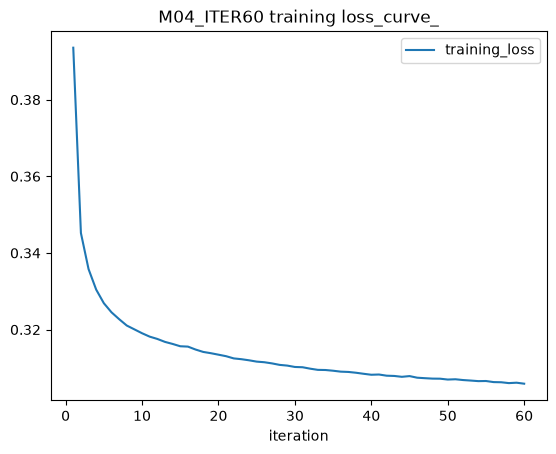

In [62]:
import importlib
import dcc_data.mission2_model_experiments as mission2_model_experiments_module
if not hasattr(mission2_model_experiments_module, 'run_internal_m04_reference'):
    mission2_model_experiments_module = importlib.reload(mission2_model_experiments_module)
    print('Reloaded model-experiment helpers without restarting the kernel.')

from dcc_data.mission2_model_experiments import (
    M04_CONVERGENCE_CHECK_CONFIG,
    M04_CONVERGENCE_CHECK_ID,
    compare_m04_convergence_check,
    run_internal_m04_reference,
    run_internal_m04_convergence_check,
)

m04_config_diff = {
    name for name in M04_MLP_CONFIG
    if M04_MLP_CONFIG[name] != M04_CONVERGENCE_CHECK_CONFIG[name]
}
assert m04_config_diff == {'max_iter'}
assert M04_MLP_CONFIG['max_iter'] == 30
assert M04_CONVERGENCE_CHECK_CONFIG['max_iter'] == 60
print(M04_CONVERGENCE_CHECK_ID, dict(M04_CONVERGENCE_CHECK_CONFIG))

RUN_INTERNAL_M04_CONVERGENCE_CHECK = False
RUN_REBUILD_M04_REFERENCE = False
if prepared_internal is None:
    raise RuntimeError('STOP: Checkpoint C의 fixed internal payload가 필요합니다.')
if 'm04_iter60_result' not in globals():
    if not RUN_INTERNAL_M04_CONVERGENCE_CHECK:
        raise RuntimeError('STOP: M04-60 result가 없습니다. Ctrl+F `RUN_INTERNAL_M04_CONVERGENCE_CHECK = False`; 직접 True로 바꾼 경우에만 실행하세요.')
    m04_iter60_result = run_internal_m04_convergence_check(
        prepared_internal, allow_fit=RUN_INTERNAL_M04_CONVERGENCE_CHECK
    )
else:
    print('Reusing existing M04-60 result; no M04-60 fit is executed.')
if m04_iter60_result.scaler is not prepared_internal.scaler:
    raise RuntimeError('STOP: M04-60 result is stale for current prepared_internal; it is not refitted automatically.')

m04_internal_result = next(
    (result for result in screening_results if result.experiment_id == 'M04'),
    None,
)
m04_reference_is_current = (
    m04_internal_result is not None
    and m04_internal_result.scaler is prepared_internal.scaler
)
if not m04_reference_is_current:
    stale_scaler_id = (
        None if m04_internal_result is None else id(m04_internal_result.scaler)
    )
    print(
        'STALE M04-30 reference detected:',
        {'reference_scaler_id': stale_scaler_id, 'current_scaler_id': id(prepared_internal.scaler)},
    )
    if not RUN_REBUILD_M04_REFERENCE:
        raise RuntimeError('STOP: Ctrl+F `RUN_REBUILD_M04_REFERENCE = False`; M04-30 reference 하나만 재생성하려면 True로 바꾸세요.')
    m04_internal_result = run_internal_m04_reference(
        prepared_internal, allow_fit=RUN_REBUILD_M04_REFERENCE
    )
    print('Rebuilt only M04-30 reference on current prepared_internal.')
if dict(m04_internal_result.model_config) != dict(M04_MLP_CONFIG):
    raise RuntimeError('STOP: rebuilt/reference M04 config differs from frozen max_iter=30 contract.')
if m04_internal_result.scaler is not prepared_internal.scaler:
    raise RuntimeError('STOP: M04-30 reference does not use current prepared_internal.scaler.')
if m04_iter60_result.scaler is not prepared_internal.scaler:
    raise RuntimeError('STOP: M04-60 result does not use current prepared_internal.scaler.')
m04_iter60_base_report = build_standalone_diagnostic_report(
    m04_iter60_result,
    training_tracking=internal_training_tracking,
    evaluation_tracking=internal_validation_tracking,
)
m04_iter60_report = augment_model_report(
    m04_iter60_result, m04_iter60_base_report
)
m04_iter60_comparison = compare_m04_convergence_check(
    m04_internal_result, m04_iter60_result
)
mlp_convergence = m04_iter60_result.fit_audit['mlp_convergence']
display(pd.DataFrame([{
    'ConvergenceWarning': mlp_convergence['convergence_warning_raised'],
    'warning_messages': mlp_convergence['convergence_warning_messages'],
    'n_iter_': mlp_convergence['n_iter'],
    'max_iter': mlp_convergence['max_iter'],
    'reached_max_iter': mlp_convergence['reached_max_iter'],
    'initial_loss': mlp_convergence['initial_loss'],
    'final_loss': mlp_convergence['final_loss'],
    'tail_loss_delta': mlp_convergence['tail_loss_delta'],
    'tail_loss_slope': mlp_convergence['tail_loss_slope'],
    'Accuracy': m04_iter60_result.metrics['accuracy'],
    'Recall speaker=0': m04_iter60_result.metrics['recall_speaker_0'],
    'Recall speaker=1': m04_iter60_result.metrics['recall_speaker_1'],
    'confusion matrix': m04_iter60_result.metrics['confusion_matrix'],
}]))
display(pd.DataFrame([m04_iter60_comparison]))
loss_curve_frame = pd.DataFrame({
    'iteration': np.arange(1, mlp_convergence['loss_curve_length'] + 1),
    'training_loss': mlp_convergence['loss_curve'],
})
display(loss_curve_frame.tail(15))
loss_curve_frame.plot(x='iteration', y='training_loss', title='M04_ITER60 training loss_curve_')
display(m04_iter60_report['duration_summary'])
display(m04_iter60_report['overlap_summary'])
display(m04_iter60_report['confidence_summary'])
print('STOP: inspect convergence and paired metrics before any further tuning.')


In [63]:
import inspect
import dcc_data.mission2_model_experiments as mme

print("=== CONFIG ===")
print(mme.M04_CONVERGENCE_CHECK_CONFIG)

print("\n=== RUNNER ===")
print(inspect.getsource(mme.run_internal_m04_convergence_check))

print("\n=== COMPARISON ===")
print(inspect.getsource(mme.compare_m04_convergence_check))

=== CONFIG ===
{'hidden_layer_sizes': (64,), 'activation': 'relu', 'solver': 'adam', 'alpha': 0.0001, 'batch_size': 1024, 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_iter': 60, 'shuffle': True, 'random_state': 42, 'tol': 0.0001, 'early_stopping': False, 'n_iter_no_change': 10}

=== RUNNER ===
def run_internal_m04_convergence_check(
    prepared: PreparedComparison, *, allow_fit: bool = False
) -> ModelExperimentResult:
    """Run the max_iter=60 M04 check on the fixed internal split only."""

    if prepared.evaluation_scope != "Training/internal_validation":
        raise ValueError(
            "M04 convergence check requires Training/internal_validation"
        )
    if not allow_fit:
        raise RuntimeError("allow_fit=True is required for any model fit")
    model = build_m04_convergence_check_model()
    with warnings.catch_warnings(record=True) as observed_warnings:
        warnings.simplefilter("always", ConvergenceWarning)
        result = _run_model(
   

M04_ITER100 {'hidden_layer_sizes': (64,), 'activation': 'relu', 'solver': 'adam', 'alpha': 0.0001, 'batch_size': 1024, 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_iter': 100, 'shuffle': True, 'random_state': 42, 'tol': 0.0001, 'early_stopping': False, 'n_iter_no_change': 10}
Finished M04_ITER100 fit.


,ConvergenceWarning,warning_messages,n_iter_,max_iter,reached_max_iter,initial_loss,final_loss,tail_loss_delta,tail_loss_slope,Accuracy,Recall speaker=0,Recall speaker=1,confusion matrix
0,True,(Stochastic Optimizer: Maximum iterations (100...,100,100,True,0.39357,0.303855,-0.000199,-0.00004,0.859532,0.815608,0.900043,"[[69613, 15738], [9250, 83290]]"


,reference_id,candidate_id,evaluation_rows,m04_accuracy,iter100_accuracy,accuracy_delta,m04_confusion_matrix,iter100_confusion_matrix,m04_recall_speaker_0,iter100_recall_speaker_0,...,m04_wrong_to_iter100_correct,m04_correct_to_iter100_wrong,prediction_disagreement_count,prediction_disagreement_rate,convergence_warning_raised,n_iter,max_iter,final_loss,tail_loss_delta,tail_loss_slope
0,M04,M04_ITER100,177891,0.857952,0.859532,0.00158,"[[68806, 16545], [8724, 83816]]","[[69613, 15738], [9250, 83290]]",0.806153,0.815608,...,2797,2516,5313,0.029867,True,100,100,0.303855,-0.000199,-0.00004


,iteration,training_loss
85,86,0.304492
86,87,0.304423
87,88,0.304239
88,89,0.304452
89,90,0.304266
90,91,0.304053
91,92,0.304203
92,93,0.304170
93,94,0.304164
94,95,0.304003


,slice,count,accuracy
0,q25_q75,88589,0.842723
1,q75_q95,35967,0.918453
2,q05_q25,35746,0.819868
3,q00_q05,8687,0.854956
4,q95_q100,8902,0.952483


,slice,count,accuracy
0,no_overlap,99310,0.893837
1,overlap,78581,0.816177


,slice,count,accuracy
0,>=0.90,104130,0.972150
1,0.60-0.70,21626,0.611532
2,0.80-0.90,22740,0.849340
3,<0.60,13006,0.541289
4,0.70-0.80,16389,0.737934


STOP: inspect M04-30 / M04-60 / M04-100 convergence and paired metrics before the next experiment.


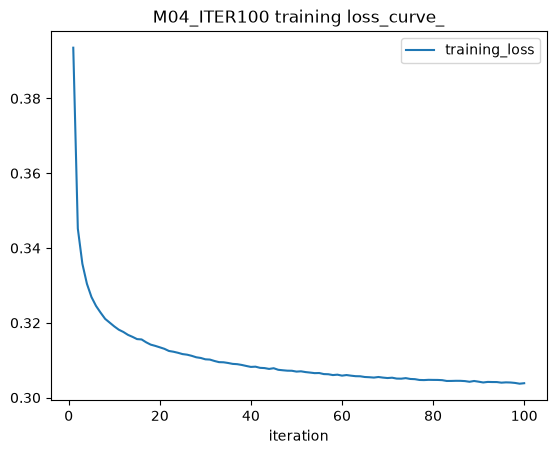

In [64]:
import warnings
from dataclasses import replace

import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.neural_network import MLPClassifier

import dcc_data.mission2_model_experiments as mme


# ============================================================
# M04_ITER100 — max_iter만 100으로 변경
# ============================================================

M04_ITER100_ID = "M04_ITER100"

M04_ITER100_CONFIG = {
    **dict(M04_MLP_CONFIG),
    "max_iter": 100,
}

# max_iter 이외에는 M04와 완전히 같아야 함
m04_iter100_config_diff = {
    name
    for name in M04_MLP_CONFIG
    if M04_MLP_CONFIG[name] != M04_ITER100_CONFIG[name]
}

assert m04_iter100_config_diff == {"max_iter"}
assert M04_MLP_CONFIG["max_iter"] == 30
assert M04_ITER100_CONFIG["max_iter"] == 100

print(M04_ITER100_ID, M04_ITER100_CONFIG)


# ============================================================
# 실행 조건 확인
# ============================================================

if prepared_internal is None:
    raise RuntimeError(
        "STOP: Checkpoint C의 fixed internal payload가 필요합니다."
    )

# 현재 M04-30 reference가 같은 scaler를 쓰는지 확인
if m04_internal_result.scaler is not prepared_internal.scaler:
    raise RuntimeError(
        "STOP: 현재 m04_internal_result가 prepared_internal과 "
        "같은 scaler 객체를 사용하지 않습니다."
    )


# ============================================================
# M04_ITER100 실행
# 기존 결과가 있으면 재학습하지 않음
# ============================================================

RUN_INTERNAL_M04_ITER100 = False

if "m04_iter100_result" not in globals():

    if not RUN_INTERNAL_M04_ITER100:
        raise RuntimeError(
            "STOP: M04_ITER100을 실행하려면 "
            "RUN_INTERNAL_M04_ITER100 = True로 바꾸세요."
        )

    model_iter100 = MLPClassifier(**M04_ITER100_CONFIG)

    with warnings.catch_warnings(record=True) as observed_warnings:
        warnings.simplefilter("always", ConvergenceWarning)

        m04_iter100_result = mme._run_model(
            prepared_internal,
            experiment_id=M04_ITER100_ID,
            model_name="MLPClassifier",
            model_config=M04_ITER100_CONFIG,
            model=model_iter100,
            allow_fit=True,
        )

    convergence_messages = tuple(
        str(observed.message)
        for observed in observed_warnings
        if issubclass(observed.category, ConvergenceWarning)
    )

    m04_iter100_convergence = mme.summarize_mlp_convergence(
        model_iter100,
        convergence_warning_messages=convergence_messages,
    )

    m04_iter100_result = replace(
        m04_iter100_result,
        fit_audit={
            **dict(m04_iter100_result.fit_audit),
            "mlp_convergence": m04_iter100_convergence,
        },
    )

    print("Finished M04_ITER100 fit.")

else:
    print(
        "Reusing existing M04_ITER100 result; "
        "no M04_ITER100 fit is executed."
    )


# ============================================================
# 동일 payload / scaler 검증
# ============================================================

if m04_iter100_result.scaler is not prepared_internal.scaler:
    raise RuntimeError(
        "STOP: M04_ITER100 result is stale for current prepared_internal."
    )

mme._validate_shared_result_payload(
    m04_internal_result,
    m04_iter100_result,
)


# ============================================================
# Diagnostic report
# ============================================================

m04_iter100_base_report = build_standalone_diagnostic_report(
    m04_iter100_result,
    training_tracking=internal_training_tracking,
    evaluation_tracking=internal_validation_tracking,
)

m04_iter100_report = augment_model_report(
    m04_iter100_result,
    m04_iter100_base_report,
)

mlp_iter100_convergence = (
    m04_iter100_result.fit_audit["mlp_convergence"]
)


# ============================================================
# M04-30 vs M04-100 paired comparison
# ============================================================

paired_100 = mme.calculate_paired_prediction_changes(
    y_true=m04_internal_result.y_true,
    m00_pred=m04_internal_result.y_pred,
    m01_pred=m04_iter100_result.y_pred,
    m00_record_keys=m04_internal_result.fit_audit[
        "validation_record_keys"
    ],
    m01_record_keys=m04_iter100_result.fit_audit[
        "validation_record_keys"
    ],
)

m04_iter100_comparison = {
    "reference_id": "M04",
    "candidate_id": M04_ITER100_ID,
    "evaluation_rows": int(len(m04_internal_result.y_true)),

    "m04_accuracy":
        float(m04_internal_result.metrics["accuracy"]),

    "iter100_accuracy":
        float(m04_iter100_result.metrics["accuracy"]),

    "accuracy_delta":
        float(
            m04_iter100_result.metrics["accuracy"]
            - m04_internal_result.metrics["accuracy"]
        ),

    "m04_confusion_matrix":
        m04_internal_result.metrics["confusion_matrix"],

    "iter100_confusion_matrix":
        m04_iter100_result.metrics["confusion_matrix"],

    "m04_recall_speaker_0":
        float(
            m04_internal_result.metrics["recall_speaker_0"]
        ),

    "iter100_recall_speaker_0":
        float(
            m04_iter100_result.metrics["recall_speaker_0"]
        ),

    "recall_speaker_0_delta":
        float(
            m04_iter100_result.metrics["recall_speaker_0"]
            - m04_internal_result.metrics["recall_speaker_0"]
        ),

    "m04_recall_speaker_1":
        float(
            m04_internal_result.metrics["recall_speaker_1"]
        ),

    "iter100_recall_speaker_1":
        float(
            m04_iter100_result.metrics["recall_speaker_1"]
        ),

    "recall_speaker_1_delta":
        float(
            m04_iter100_result.metrics["recall_speaker_1"]
            - m04_internal_result.metrics["recall_speaker_1"]
        ),

    "correct_count_delta":
        int(
            m04_iter100_result.metrics["correct_count"]
            - m04_internal_result.metrics["correct_count"]
        ),

    "both_correct":
        paired_100["both_correct"],

    "both_wrong":
        paired_100["both_wrong"],

    "m04_wrong_to_iter100_correct":
        paired_100["m00_wrong_to_m01_correct"],

    "m04_correct_to_iter100_wrong":
        paired_100["m00_correct_to_m01_wrong"],

    "prediction_disagreement_count":
        paired_100["prediction_disagreement_count"],

    "prediction_disagreement_rate":
        paired_100["prediction_disagreement_rate"],

    "convergence_warning_raised":
        bool(
            mlp_iter100_convergence[
                "convergence_warning_raised"
            ]
        ),

    "n_iter":
        int(mlp_iter100_convergence["n_iter"]),

    "max_iter":
        int(mlp_iter100_convergence["max_iter"]),

    "final_loss":
        float(mlp_iter100_convergence["final_loss"]),

    "tail_loss_delta":
        float(mlp_iter100_convergence["tail_loss_delta"]),

    "tail_loss_slope":
        float(mlp_iter100_convergence["tail_loss_slope"]),
}


# ============================================================
# 결과 출력
# ============================================================

display(pd.DataFrame([{
    "ConvergenceWarning":
        mlp_iter100_convergence[
            "convergence_warning_raised"
        ],

    "warning_messages":
        mlp_iter100_convergence[
            "convergence_warning_messages"
        ],

    "n_iter_":
        mlp_iter100_convergence["n_iter"],

    "max_iter":
        mlp_iter100_convergence["max_iter"],

    "reached_max_iter":
        mlp_iter100_convergence["reached_max_iter"],

    "initial_loss":
        mlp_iter100_convergence["initial_loss"],

    "final_loss":
        mlp_iter100_convergence["final_loss"],

    "tail_loss_delta":
        mlp_iter100_convergence["tail_loss_delta"],

    "tail_loss_slope":
        mlp_iter100_convergence["tail_loss_slope"],

    "Accuracy":
        m04_iter100_result.metrics["accuracy"],

    "Recall speaker=0":
        m04_iter100_result.metrics["recall_speaker_0"],

    "Recall speaker=1":
        m04_iter100_result.metrics["recall_speaker_1"],

    "confusion matrix":
        m04_iter100_result.metrics["confusion_matrix"],
}]))

display(pd.DataFrame([m04_iter100_comparison]))


# ============================================================
# Loss curve
# ============================================================

loss_curve_iter100 = pd.DataFrame({
    "iteration": np.arange(
        1,
        mlp_iter100_convergence["loss_curve_length"] + 1
    ),
    "training_loss":
        mlp_iter100_convergence["loss_curve"],
})

display(loss_curve_iter100.tail(15))

loss_curve_iter100.plot(
    x="iteration",
    y="training_loss",
    title="M04_ITER100 training loss_curve_",
)


# ============================================================
# Slice diagnostics
# ============================================================

display(m04_iter100_report["duration_summary"])
display(m04_iter100_report["overlap_summary"])
display(m04_iter100_report["confidence_summary"])


print(
    "STOP: inspect M04-30 / M04-60 / M04-100 "
    "convergence and paired metrics before the next experiment."
)